In [1]:
# 01. Install FaceNet-PyTorch
# Install the face-recognition package without changing its dependencies.

%pip install --no-deps facenet-pytorch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# 02. Install KaggleHub
# Install the package used to download and cache the dataset.

%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# 03. Load and Check the Pretrained Model
# Load VGGFace2-pretrained FaceNet, select the available device,
# and verify that the model produces 512-dimensional embeddings.

import torch
from facenet_pytorch import InceptionResnetV1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = InceptionResnetV1(
    pretrained="vggface2",
    classify=False
).to(device).eval()

print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

with torch.no_grad():
    embeddings = model(torch.randn(2, 3, 160, 160, device=device))

print("Embedding shape:", embeddings.shape)

PyTorch: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti
Embedding shape: torch.Size([2, 512])


In [4]:
# 04. Download the Dataset
# Download or locate the cached version-1 CASIA-WebFace dataset.

import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download(
        "yakhyokhuja/webface-112x112/versions/1"
    )
)

In [5]:
# 05. Inspect Dataset Structure and Identity Counts
# Count images in each identity folder and identify subjects
# with at least 50 images available for the pilot.

print("Dataset location:", dataset_path)
print("Contents:", [p.name for p in dataset_path.iterdir()])\

import pandas as pd

data_root = dataset_path / "webface_112x112"
image_extensions = {".jpg", ".jpeg", ".png"}

identity_counts = pd.DataFrame([
    {
        "identity": folder.name,
        "images": sum(
            file.is_file() and file.suffix.lower() in image_extensions
            for file in folder.iterdir()
        )
    }
    for folder in data_root.iterdir()
    if folder.is_dir()
]).sort_values("images", ascending=False).reset_index(drop=True)

eligible_identities = identity_counts[
    identity_counts["images"] >= 50
].copy()

print("Total identities:", len(identity_counts))
print("Identities with at least 50 images:", len(eligible_identities))

display(eligible_identities.head(20))

Dataset location: C:\Users\yosep\.cache\kagglehub\datasets\yakhyokhuja\webface-112x112\versions\1
Contents: ['webface_112x112']
Total identities: 10572
Identities with at least 50 images: 2511


,identity,images
0,id_819,802
1,id_3410,744
2,id_138,710
3,id_1321,651
4,id_3384,648
5,id_2188,631
6,id_3024,628
7,id_872,621
8,id_2749,615
9,id_4111,609


In [6]:
# 06. Select the Pilot Dataset
# Use seed 42 to select 20 eligible identities and 50 images
# per identity without modifying the original dataset.

import random

SEED = 42
N_IDENTITIES = 20
IMAGES_PER_IDENTITY = 50

# Sort before sampling so results do not depend on folder-listing order.
candidates = eligible_identities.sort_values("identity").reset_index(drop=True)

selected_identities = candidates.sample(
    n=N_IDENTITIES,
    random_state=SEED
).sort_values("identity").reset_index(drop=True)

rng = random.Random(SEED)
pilot_images = {}

for identity in selected_identities["identity"]:
    image_paths = sorted(
        file
        for file in (data_root / identity).iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

    pilot_images[identity] = rng.sample(
        image_paths,
        k=IMAGES_PER_IDENTITY
    )

print("Selected identities:", len(pilot_images))
print("Selected images:", sum(map(len, pilot_images.values())))

display(selected_identities)

Selected identities: 20
Selected images: 1000


,identity,images
0,id_125,99
1,id_1658,89
2,id_1664,125
3,id_2067,55
4,id_2527,146
5,id_2776,50
6,id_2794,86
7,id_2966,108
8,id_3421,79
9,id_3966,81


In [7]:
# 07. Create Disjoint Data Partitions
# Split each identity into 25 training, 5 enrollment,
# 10 validation, and 10 test images; check for path overlap.

import random
import pandas as pd

split_rng = random.Random(SEED)
data_splits = {}
split_rows = []

for identity in sorted(pilot_images):
    paths = sorted(pilot_images[identity])
    split_rng.shuffle(paths)

    data_splits[identity] = {
        "train": paths[:25],
        "enrollment": paths[25:30],
        "validation": paths[30:40],
        "test": paths[40:50],
    }

    # Check that each image belongs to exactly one partition.
    all_paths = [
        path
        for partition in data_splits[identity].values()
        for path in partition
    ]
    assert len(all_paths) == len(set(all_paths)) == 50

    split_rows.append({
        "identity": identity,
        **{
            name: len(paths)
            for name, paths in data_splits[identity].items()
        },
    })

split_summary = pd.DataFrame(split_rows)
display(split_summary)

print("Total images per partition:")
print(split_summary.drop(columns="identity").sum())

,identity,train,enrollment,validation,test
0,id_125,25,5,10,10
1,id_1658,25,5,10,10
2,id_1664,25,5,10,10
3,id_2067,25,5,10,10
4,id_2527,25,5,10,10
5,id_2776,25,5,10,10
6,id_2794,25,5,10,10
7,id_2966,25,5,10,10
8,id_3421,25,5,10,10
9,id_3966,25,5,10,10


Total images per partition:
train         500
enrollment    100
validation    200
test          200
dtype: int64


In [8]:
# 08. Preprocess Images and Extract Pretrained Embeddings
# Resize and standardize face images, extract enrollment and
# validation embeddings, and construct normalized identity templates.



import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm

# PILToTensor preserves the original 0–255 pixel scale.
preprocess = transforms.Compose([
    transforms.Resize(
        (160, 160),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.PILToTensor(),
])


def load_face(path):
    with Image.open(path) as image:
        tensor = preprocess(image.convert("RGB")).float()

    return (tensor - 127.5) / 128.0


@torch.inference_mode()
def extract_embeddings(image_paths, batch_size=32):
    model.eval()
    outputs = []

    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]

        batch = torch.stack([
            load_face(path) for path in batch_paths
        ]).to(device)

        embeddings = model(batch)
        outputs.append(F.normalize(embeddings, dim=1).cpu())

    return torch.cat(outputs, dim=0)


clean_embeddings = {}
clean_templates = {}

for identity in tqdm(sorted(data_splits), desc="Extracting clean embeddings"):
    enrollment = extract_embeddings(
        data_splits[identity]["enrollment"]
    )
    validation = extract_embeddings(
        data_splits[identity]["validation"]
    )

    clean_embeddings[identity] = {
        "enrollment": enrollment,
        "validation": validation,
    }

    # Average the five enrollment embeddings, then normalize.
    clean_templates[identity] = F.normalize(
        enrollment.mean(dim=0),
        dim=0
    )

example_identity = sorted(data_splits)[0]

print("Example identity:", example_identity)
print(
    "Enrollment embeddings:",
    clean_embeddings[example_identity]["enrollment"].shape
)
print(
    "Validation embeddings:",
    clean_embeddings[example_identity]["validation"].shape
)
print("Template:", clean_templates[example_identity].shape)

Extracting clean embeddings:   0%|          | 0/20 [00:00<?, ?it/s]

Example identity: id_125
Enrollment embeddings: torch.Size([5, 512])
Validation embeddings: torch.Size([10, 512])
Template: torch.Size([512])


Genuine comparisons: 200
Impostor comparisons: 3800


,count,mean,std,min,25%,50%,75%,max
genuine,,,,,,,,
Impostor,3800.0,0.006728,0.147437,-0.425462,-0.098672,0.003990,0.106230,0.569092
Genuine,200.0,0.719390,0.162838,-0.109069,0.635833,0.744537,0.835824,0.938682


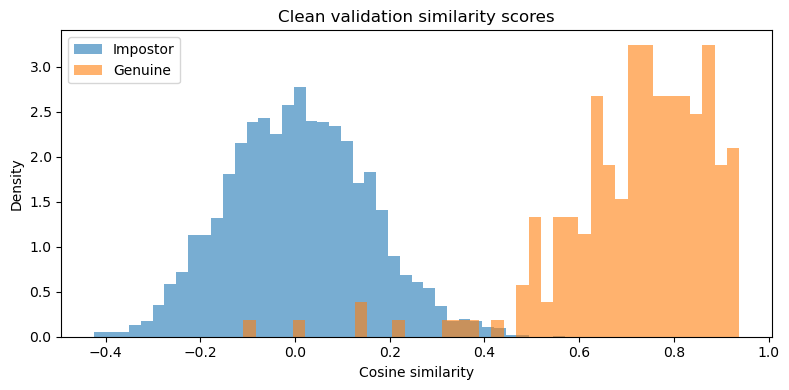

In [9]:
# 09. Calculate Clean Validation Similarities
# Compare each validation embedding with every enrollment template,
# distinguish genuine from impostor comparisons, and plot their scores.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

identities = sorted(clean_templates)

# Each row is one normalized identity template.
template_matrix = torch.stack([
    clean_templates[identity] for identity in identities
])

score_frames = []

for identity in identities:
    embeddings = clean_embeddings[identity]["validation"]

    # Dot products equal cosine similarities for normalized vectors.
    similarities = (embeddings @ template_matrix.T).numpy()

    score_frames.append(pd.DataFrame({
        "probe_identity": identity,
        "probe_index": np.repeat(
            np.arange(len(embeddings)), len(identities)
        ),
        "claimed_identity": np.tile(
            identities, len(embeddings)
        ),
        "similarity": similarities.reshape(-1),
    }))

clean_validation_scores = pd.concat(score_frames, ignore_index=True)

clean_validation_scores["genuine"] = (
    clean_validation_scores["probe_identity"]
    == clean_validation_scores["claimed_identity"]
)

genuine_scores = clean_validation_scores.loc[
    clean_validation_scores["genuine"], "similarity"
].to_numpy(dtype=np.float64)

impostor_scores = clean_validation_scores.loc[
    ~clean_validation_scores["genuine"], "similarity"
].to_numpy(dtype=np.float64)

print("Genuine comparisons:", len(genuine_scores))
print("Impostor comparisons:", len(impostor_scores))

display(
    clean_validation_scores.groupby("genuine")["similarity"]
    .describe()
    .rename(index={False: "Impostor", True: "Genuine"})
)

plt.figure(figsize=(8, 4))

plt.hist(
    impostor_scores, bins=40, alpha=0.6,
    density=True, label="Impostor"
)
plt.hist(
    genuine_scores, bins=40, alpha=0.6,
    density=True, label="Genuine"
)

plt.xlabel("Cosine similarity")
plt.ylabel("Density")
plt.title("Clean validation similarity scores")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# 10. Calibrate the Pretrained Verification Threshold
# Select a threshold permitting at most 1% empirical validation
# false matches and report the resulting false non-match rate.

target_fmr = 0.01

# Allow at most 1% of validation impostor comparisons to pass.
allowed_matches = int(np.floor(target_fmr * len(impostor_scores)))
descending_scores = np.sort(impostor_scores)[::-1]

# Accept when similarity >= threshold.
# Move above the first score that would exceed the allowed count.
clean_threshold = np.nextafter(
    descending_scores[allowed_matches],
    np.inf
)

validation_fmr = np.mean(impostor_scores >= clean_threshold)
validation_fnmr = np.mean(genuine_scores < clean_threshold)

print(f"Clean threshold: {clean_threshold:.6f}")
print(f"Validation FMR:  {validation_fmr:.2%}")
print(f"Validation FNMR: {validation_fnmr:.2%}")

Clean threshold: 0.371294
Validation FMR:  1.00%
Validation FNMR: 3.50%


In [11]:
# 11. Identify Low-Scoring Genuine Probes
# Locate the five lowest genuine validation scores and recover
# their image paths for inspection.

lowest_genuine = (
    clean_validation_scores[
        clean_validation_scores["genuine"]
    ]
    .nsmallest(5, "similarity")
    .copy()
)

lowest_genuine["image_path"] = [
    str(data_splits[identity]["validation"][int(index)])
    for identity, index in zip(
        lowest_genuine["probe_identity"],
        lowest_genuine["probe_index"]
    )
]

display(
    lowest_genuine[
        ["probe_identity", "probe_index", "similarity", "image_path"]
    ]
)

,probe_identity,probe_index,similarity,image_path
984,id_2527,9,-0.109069,C:\Users\yosep\.cache\kagglehub\datasets\yakhy...
3336,id_810,6,0.015982,C:\Users\yosep\.cache\kagglehub\datasets\yakhy...
3738,id_9383,6,0.137150,C:\Users\yosep\.cache\kagglehub\datasets\yakhy...
824,id_2527,1,0.148171,C:\Users\yosep\.cache\kagglehub\datasets\yakhy...
3879,id_9486,3,0.229057,C:\Users\yosep\.cache\kagglehub\datasets\yakhy...


Training images analyzed: 500

Image dimensions:


,width,height,images
0,112,112,500



Image-statistic summary:


,brightness,contrast,sharpness
count,500.000000,500.000000,500.000000
mean,0.422571,0.215993,0.007080
std,0.109545,0.048466,0.006923
min,0.111551,0.067596,0.000119
25%,0.353562,0.182980,0.002123
50%,0.423928,0.214996,0.004838
75%,0.490553,0.252107,0.009660
max,0.829155,0.396261,0.042497


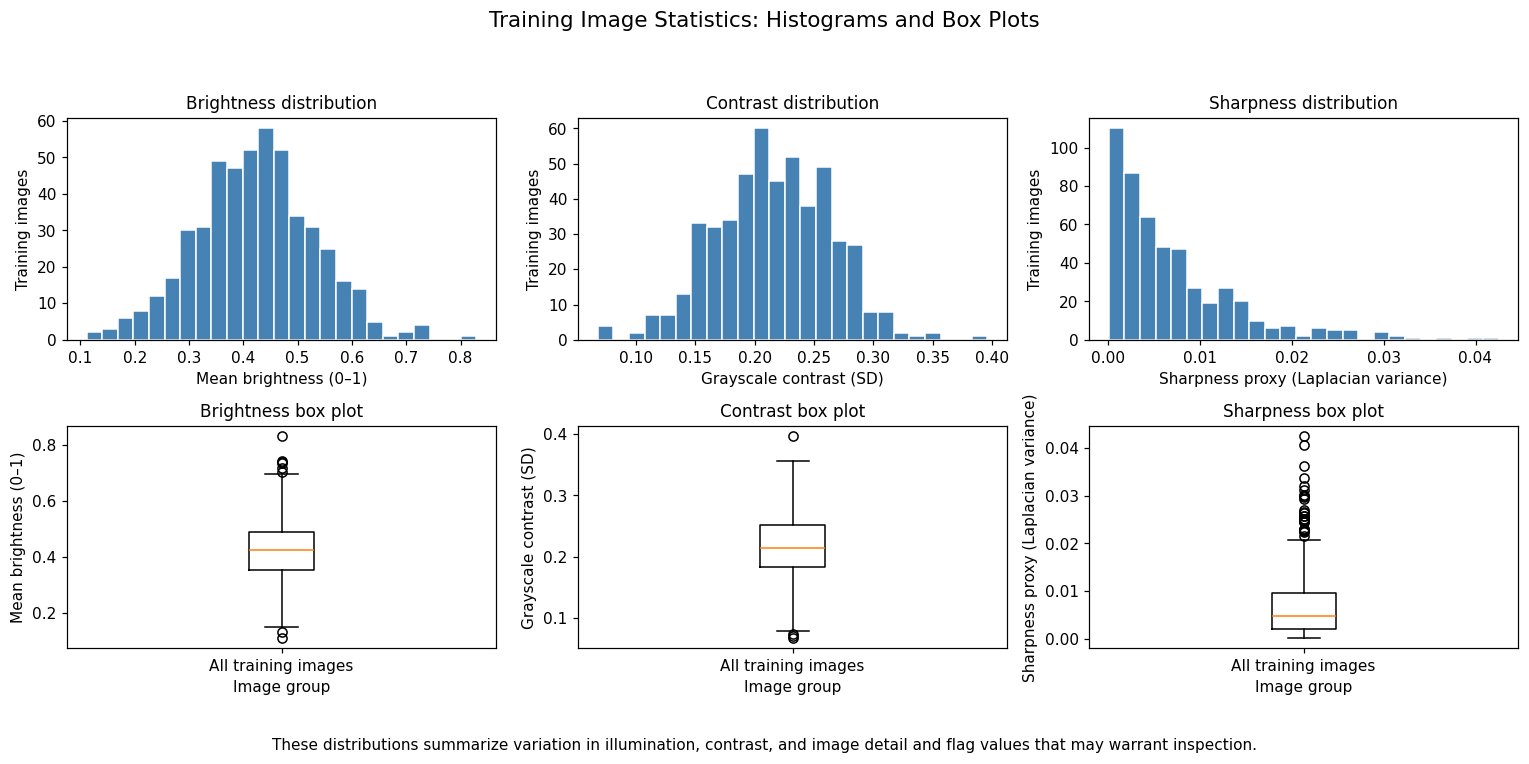

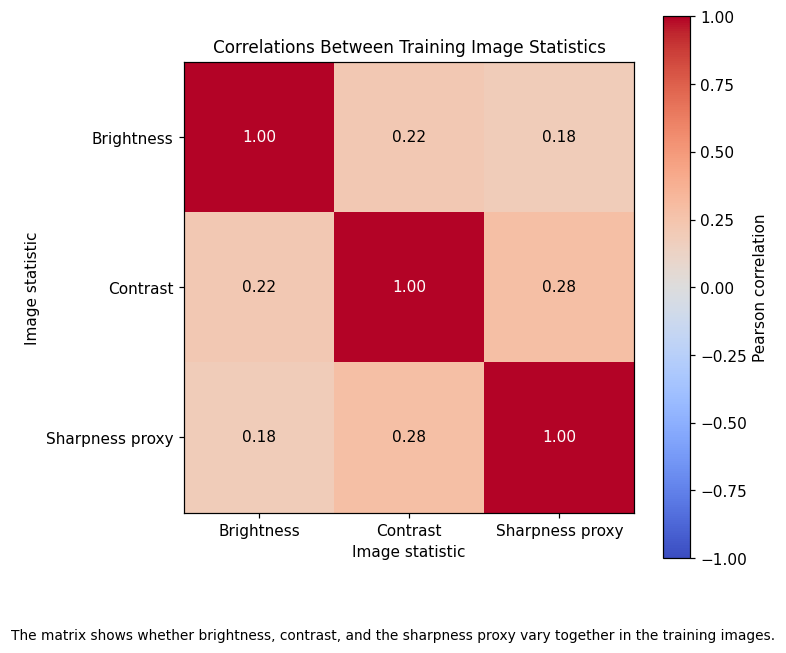

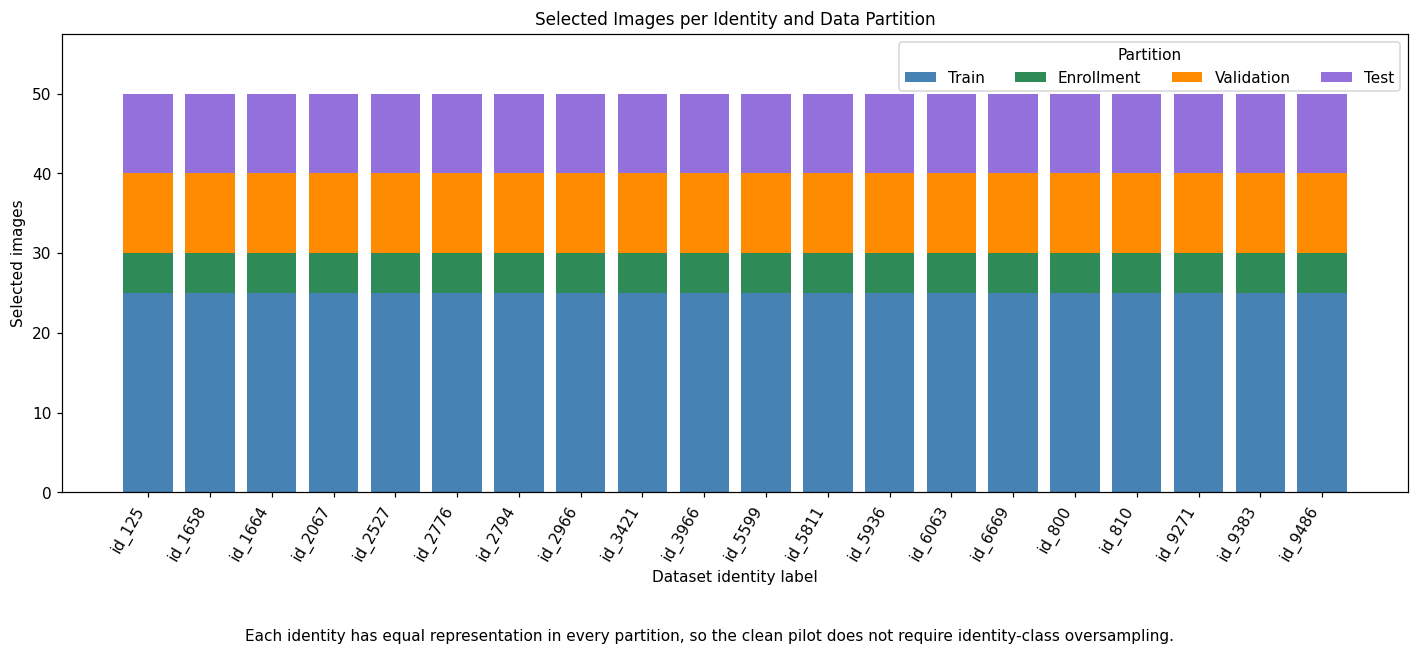

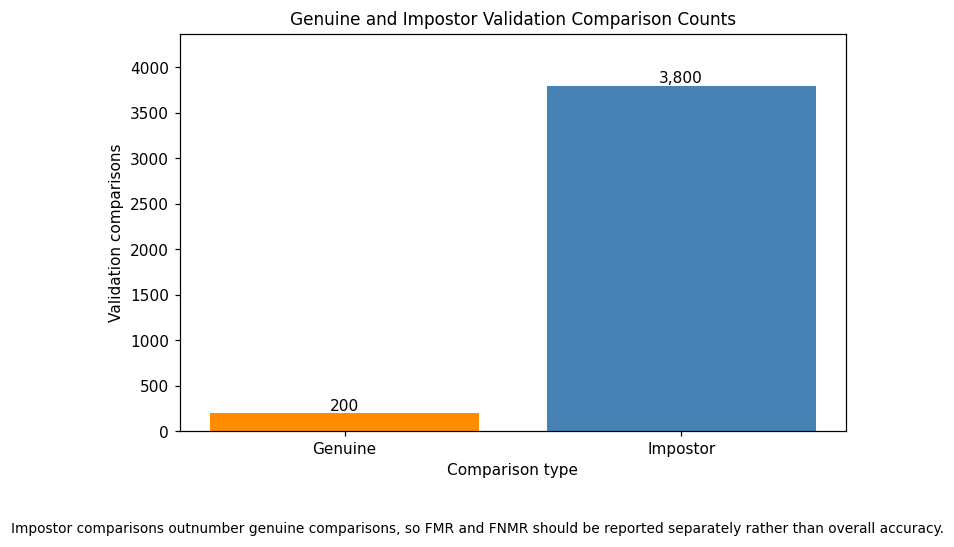

Validation comparison ratio: 1 genuine to 19 impostor comparisons.
Retaining all comparisons is appropriate for this evaluation; they are not independent because images and templates are reused.


In [12]:
# ============================================================
# Exploratory Data Analysis — Face Verification Pilot
# Requires:
#   data_splits
#   clean_validation_scores
# ============================================================

# 12. Explore Image Statistics and Class Balance
# Plot training-image brightness, contrast, and sharpness distributions,
# their correlations, identity counts, and comparison-type counts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "font.size": 10,
})

# ------------------------------------------------------------
# 1. Compute image statistics using TRAINING IMAGES ONLY
# ------------------------------------------------------------
# Brightness: mean grayscale intensity, scaled to [0, 1].
# Contrast: standard deviation of grayscale intensity.
# Sharpness proxy: variance of a discrete Laplacian.
# Higher Laplacian variance indicates more high-frequency detail,
# but noise can also increase it; it is not a complete quality score.

eda_rows = []

for identity in sorted(data_splits):
    for path in data_splits[identity]["train"]:
        with Image.open(path) as image:
            width, height = image.size
            gray = np.asarray(
                image.convert("L"),
                dtype=np.float64
            ) / 255.0

        # Interior pixels only, avoiding artificial wraparound edges.
        laplacian = (
            gray[:-2, 1:-1]
            + gray[2:, 1:-1]
            + gray[1:-1, :-2]
            + gray[1:-1, 2:]
            - 4.0 * gray[1:-1, 1:-1]
        )

        eda_rows.append({
            "identity": identity,
            "filename": path.name,
            "width": width,
            "height": height,
            "brightness": gray.mean(),
            "contrast": gray.std(),
            "sharpness": laplacian.var(),
        })

eda_image_stats = pd.DataFrame(eda_rows)

feature_columns = ["brightness", "contrast", "sharpness"]

feature_labels = {
    "brightness": "Mean brightness (0–1)",
    "contrast": "Grayscale contrast (SD)",
    "sharpness": "Sharpness proxy (Laplacian variance)",
}

print("Training images analyzed:", len(eda_image_stats))
print("\nImage dimensions:")
display(
    eda_image_stats.groupby(["width", "height"])
    .size()
    .reset_index(name="images")
)

print("\nImage-statistic summary:")
display(eda_image_stats[feature_columns].describe())


# ------------------------------------------------------------
# Figure 1. Univariate distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for column_index, feature in enumerate(feature_columns):
    values = eda_image_stats[feature].to_numpy()

    # Histogram
    histogram_ax = axes[0, column_index]
    histogram_ax.hist(
        values,
        bins=25,
        color="steelblue",
        edgecolor="white"
    )
    histogram_ax.set_title(f"{feature.capitalize()} distribution")
    histogram_ax.set_xlabel(feature_labels[feature])
    histogram_ax.set_ylabel("Training images")

    # Box plot
    boxplot_ax = axes[1, column_index]
    boxplot_ax.boxplot(values)
    boxplot_ax.set_xticks([1])
    boxplot_ax.set_xticklabels(["All training images"])
    boxplot_ax.set_xlabel("Image group")
    boxplot_ax.set_ylabel(feature_labels[feature])
    boxplot_ax.set_title(f"{feature.capitalize()} box plot")

fig.suptitle(
    "Training Image Statistics: Histograms and Box Plots",
    fontsize=14
)

fig.text(
    0.5, 0.02,
    "These distributions summarize variation in illumination, contrast, "
    "and image detail and flag values that may warrant inspection.",
    ha="center",
    fontsize=10
)

fig.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()


# ------------------------------------------------------------
# Figure 2. Bivariate relationships: correlation matrix
# ------------------------------------------------------------

eda_correlations = eda_image_stats[feature_columns].corr()

fig, ax = plt.subplots(figsize=(7, 6))

heatmap = ax.imshow(
    eda_correlations.to_numpy(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

short_labels = ["Brightness", "Contrast", "Sharpness proxy"]

ax.set_xticks(range(len(feature_columns)))
ax.set_yticks(range(len(feature_columns)))
ax.set_xticklabels(short_labels)
ax.set_yticklabels(short_labels)

ax.set_xlabel("Image statistic")
ax.set_ylabel("Image statistic")
ax.set_title("Correlations Between Training Image Statistics")

for row in range(len(feature_columns)):
    for column in range(len(feature_columns)):
        value = eda_correlations.iloc[row, column]
        ax.text(
            column, row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Pearson correlation")

fig.text(
    0.5, 0.02,
    "The matrix shows whether brightness, contrast, and the sharpness proxy "
    "vary together in the training images.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()


# ------------------------------------------------------------
# Figure 3. Class balance: identities and partitions
# Reads partition membership, not validation/test image pixels.
# ------------------------------------------------------------

partition_names = ["train", "enrollment", "validation", "test"]
eda_identities = sorted(data_splits)

eda_class_counts = pd.DataFrame(
    {
        partition: [
            len(data_splits[identity][partition])
            for identity in eda_identities
        ]
        for partition in partition_names
    },
    index=eda_identities
)

fig, ax = plt.subplots(figsize=(13, 6))

positions = np.arange(len(eda_identities))
bottom = np.zeros(len(eda_identities))

partition_colors = [
    "steelblue", "seagreen", "darkorange", "mediumpurple"
]

for partition, color in zip(partition_names, partition_colors):
    counts = eda_class_counts[partition].to_numpy()

    ax.bar(
        positions,
        counts,
        bottom=bottom,
        label=partition.capitalize(),
        color=color
    )
    bottom += counts

ax.set_xticks(positions)
ax.set_xticklabels(eda_identities, rotation=60, ha="right")
ax.set_xlabel("Dataset identity label")
ax.set_ylabel("Selected images")
ax.set_title("Selected Images per Identity and Data Partition")
ax.legend(title="Partition", ncol=4)
ax.set_ylim(0, bottom.max() * 1.15)

identity_caption = (
    "Each identity has equal representation in every partition, "
    "so the clean pilot does not require identity-class oversampling."
    if eda_class_counts.nunique().eq(1).all()
    else
    "Unequal identity counts should be considered when interpreting "
    "aggregate metrics and choosing training sampling strategies."
)

fig.text(
    0.5, 0.02,
    identity_caption,
    ha="center",
    fontsize=10
)

fig.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


# ------------------------------------------------------------
# Figure 4. Class balance: genuine versus impostor comparisons
# ------------------------------------------------------------

genuine_count = int(clean_validation_scores["genuine"].sum())
impostor_count = int((~clean_validation_scores["genuine"]).sum())

comparison_labels = ["Genuine", "Impostor"]
comparison_counts = [genuine_count, impostor_count]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    comparison_labels,
    comparison_counts,
    color=["darkorange", "steelblue"]
)

for bar, count in zip(bars, comparison_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

ax.set_xlabel("Comparison type")
ax.set_ylabel("Validation comparisons")
ax.set_title("Genuine and Impostor Validation Comparison Counts")
ax.set_ylim(0, max(comparison_counts) * 1.15)

fig.text(
    0.5, 0.02,
    "Impostor comparisons outnumber genuine comparisons, so FMR and FNMR "
    "should be reported separately rather than overall accuracy.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

print(
    f"Validation comparison ratio: "
    f"1 genuine to {impostor_count / genuine_count:.0f} impostor comparisons."
)
print(
    "Retaining all comparisons is appropriate for this evaluation; "
    "they are not independent because images and templates are reused."
)

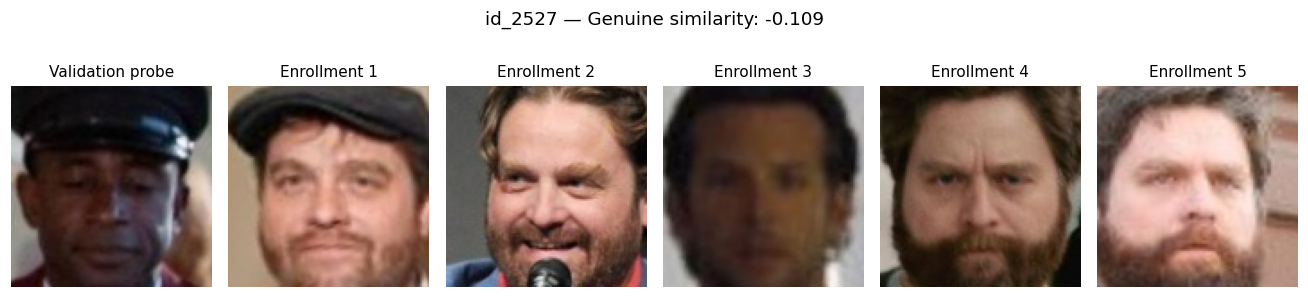

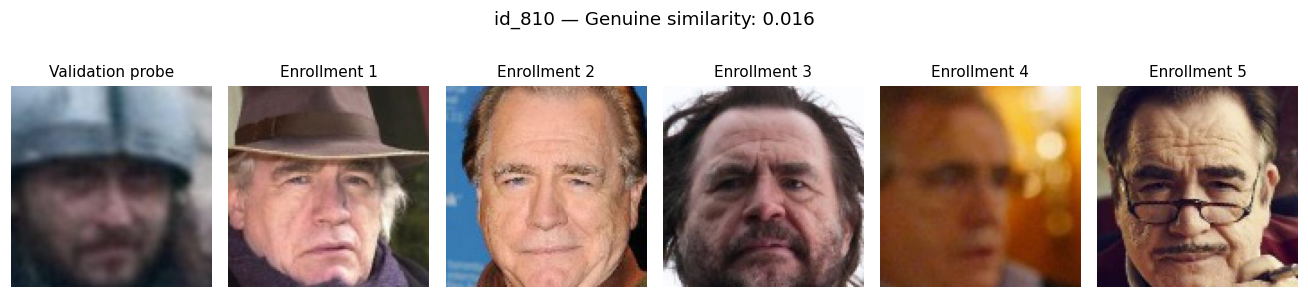

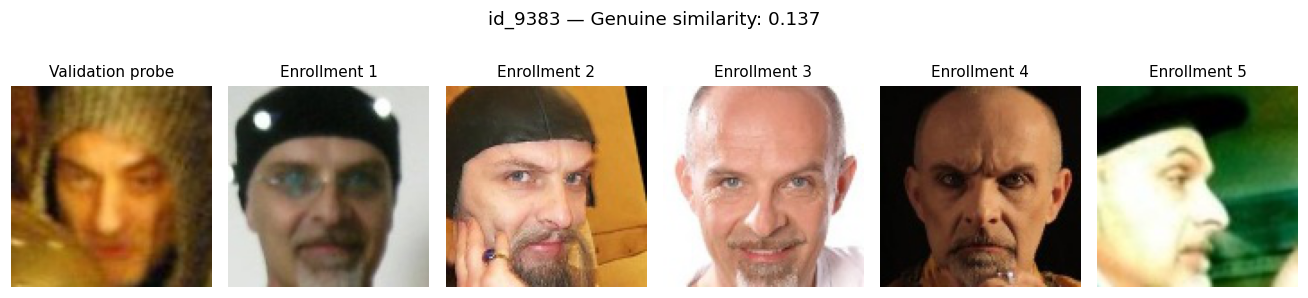

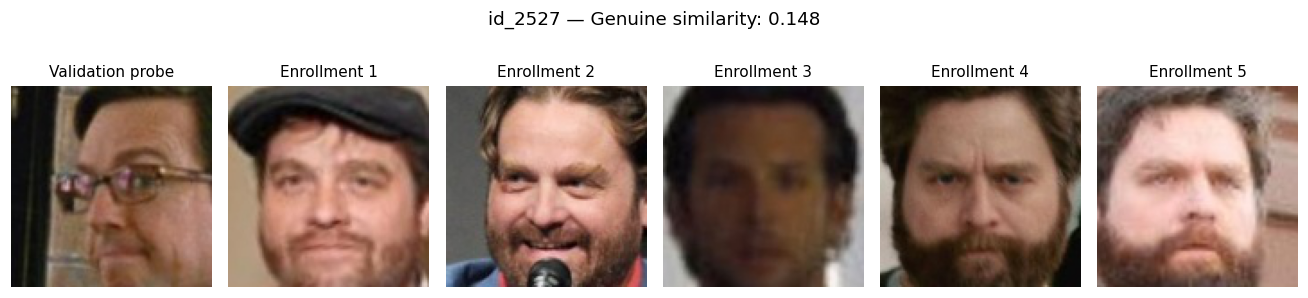

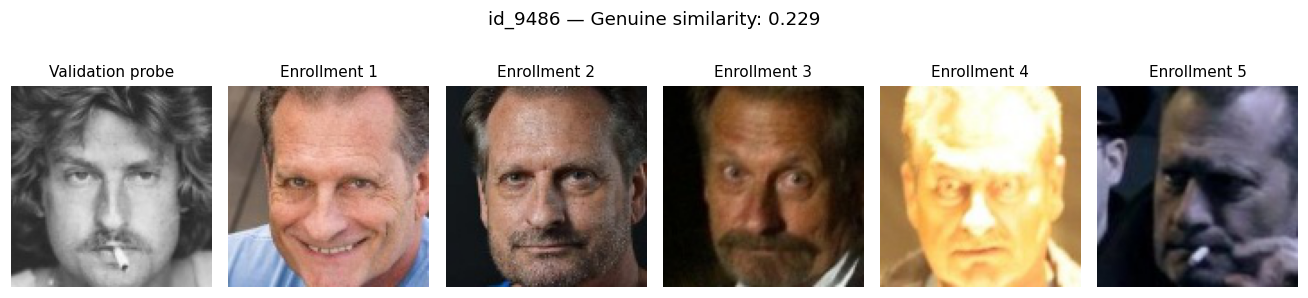

In [13]:
# 13. Inspect Difficult Validation Images
# Display low-scoring genuine probes beside their enrollment images
# to investigate possible image-quality and dataset issues.


import matplotlib.pyplot as plt
from PIL import Image

for row in lowest_genuine.itertuples(index=False):
    identity = row.probe_identity
    probe_path = data_splits[identity]["validation"][int(row.probe_index)]
    enrollment_paths = data_splits[identity]["enrollment"]

    fig, axes = plt.subplots(1, 6, figsize=(12, 3))

    for ax, path, title in zip(
        axes,
        [probe_path] + enrollment_paths,
        ["Validation probe"] + [f"Enrollment {i}" for i in range(1, 6)]
    ):
        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(title, fontsize=10)
        ax.axis("off")

    fig.suptitle(
        f"{identity} — Genuine similarity: {row.similarity:.3f}"
    )
    plt.tight_layout()
    plt.show()

In [14]:
# 14. Prepare the Clean Fine-Tuning Control
# Create correctly labeled training records and a separate model copy,
# enable the final embedding layers, and retain the starting weights.


import copy
import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

TRAIN_SEED = 42

random.seed(TRAIN_SEED)
np.random.seed(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAIN_SEED)

identity_names = sorted(data_splits)
identity_to_label = {
    identity: index
    for index, identity in enumerate(identity_names)
}

train_records = [
    (path, identity_to_label[identity])
    for identity in identity_names
    for path in data_splits[identity]["train"]
]


class FaceTrainingDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        return load_face(path), label


train_generator = torch.Generator().manual_seed(TRAIN_SEED)

train_loader = DataLoader(
    FaceTrainingDataset(train_records),
    batch_size=32,
    shuffle=True,
    generator=train_generator,
    num_workers=0,  # Simple option for Windows/Jupyter.
)

# Preserve the original pretrained model.
baseline_model = copy.deepcopy(model).to(device)
baseline_model.classify = False

# Freeze the backbone, then enable its final embedding layers.
for parameter in baseline_model.parameters():
    parameter.requires_grad = False

for layer in [baseline_model.block8, baseline_model.last_linear]:
    for parameter in layer.parameters():
        parameter.requires_grad = True

baseline_head = nn.Linear(512, len(identity_names)).to(device)

# Retain identical starting states for the later poisoned run.
fine_tuning_start = {
    "backbone": {
        name: value.detach().cpu().clone()
        for name, value in baseline_model.state_dict().items()
    },
    "head": {
        name: value.detach().cpu().clone()
        for name, value in baseline_head.state_dict().items()
    },
}

print("Training images:", len(train_records))
print("Identity classes:", len(identity_names))
print(
    "Trainable backbone parameters:",
    sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
)

Training images: 500
Identity classes: 20
Trainable backbone parameters: 2518272


In [15]:
# 15. Train the Clean Fine-Tuned Baseline
# Fine-tune the selected embedding layers and a temporary classifier
# for 10 epochs using correct labels and fixed training settings.

EPOCHS = 10
BACKBONE_LR = 1e-5
HEAD_LR = 1e-3

optimizer = torch.optim.Adam(
    [
        {
            "params": [
                p for p in baseline_model.parameters()
                if p.requires_grad
            ],
            "lr": BACKBONE_LR,
        },
        {
            "params": baseline_head.parameters(),
            "lr": HEAD_LR,
        },
    ]
)

criterion = nn.CrossEntropyLoss()
baseline_history = []

for epoch in range(EPOCHS):
    # Keep BatchNorm statistics fixed and disable backbone dropout.
    # eval() does not prevent gradient updates to enabled parameters.
    baseline_model.eval()
    baseline_head.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        embeddings = baseline_model(images)
        logits = baseline_head(embeddings)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_images += len(labels)

    epoch_loss = total_loss / total_images
    epoch_accuracy = total_correct / total_images

    baseline_history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "training_accuracy": epoch_accuracy,
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Training accuracy: {epoch_accuracy:.2%}"
    )

Epoch 01/10 | Loss: 2.9216 | Training accuracy: 47.40%
Epoch 02/10 | Loss: 2.7492 | Training accuracy: 95.00%
Epoch 03/10 | Loss: 2.5764 | Training accuracy: 96.60%
Epoch 04/10 | Loss: 2.4006 | Training accuracy: 97.20%
Epoch 05/10 | Loss: 2.2246 | Training accuracy: 97.80%
Epoch 06/10 | Loss: 2.0507 | Training accuracy: 97.60%
Epoch 07/10 | Loss: 1.8795 | Training accuracy: 98.00%
Epoch 08/10 | Loss: 1.7128 | Training accuracy: 98.00%
Epoch 09/10 | Loss: 1.5537 | Training accuracy: 98.40%
Epoch 10/10 | Loss: 1.4009 | Training accuracy: 98.60%


In [16]:
# 16. Evaluate the Fine-Tuned Baseline on Validation Data
# Regenerate enrollment templates, evaluate the original threshold,
# and calibrate a new threshold targeting 1% validation FMR.


import torch.nn.functional as F


@torch.inference_mode()
def embed_with_model(network, image_paths, batch_size=32):
    network.eval()
    outputs = []

    for start in range(0, len(image_paths), batch_size):
        paths = image_paths[start:start + batch_size]

        images = torch.stack([
            load_face(path) for path in paths
        ]).to(device)

        outputs.append(
            F.normalize(network(images), dim=1).cpu()
        )

    return torch.cat(outputs, dim=0)


baseline_templates = {}

for identity in identity_names:
    enrollment_embeddings = embed_with_model(
        baseline_model,
        data_splits[identity]["enrollment"]
    )

    baseline_templates[identity] = F.normalize(
        enrollment_embeddings.mean(dim=0),
        dim=0
    )

baseline_template_matrix = torch.stack([
    baseline_templates[identity] for identity in identity_names
])

baseline_genuine = []
baseline_impostor = []

for index, identity in enumerate(identity_names):
    validation_embeddings = embed_with_model(
        baseline_model,
        data_splits[identity]["validation"]
    )

    scores = (
        validation_embeddings @ baseline_template_matrix.T
    ).numpy()

    baseline_genuine.extend(scores[:, index].tolist())
    baseline_impostor.extend(
        np.delete(scores, index, axis=1).reshape(-1).tolist()
    )

baseline_genuine = np.asarray(baseline_genuine, dtype=np.float64)
baseline_impostor = np.asarray(baseline_impostor, dtype=np.float64)

# Compare at the original pretrained threshold.
print(f"Original threshold: {clean_threshold:.6f}")
print(
    "Fine-tuned validation FMR: ",
    f"{np.mean(baseline_impostor >= clean_threshold):.2%}"
)
print(
    "Fine-tuned validation FNMR:",
    f"{np.mean(baseline_genuine < clean_threshold):.2%}"
)

# Also calibrate a separate 1%-FMR threshold for this baseline.
allowed_matches = int(np.floor(0.01 * len(baseline_impostor)))

baseline_threshold = np.nextafter(
    np.sort(baseline_impostor)[::-1][allowed_matches],
    np.inf
)

print(f"\nFine-tuned calibrated threshold: {baseline_threshold:.6f}")
print(
    "Calibrated validation FMR: ",
    f"{np.mean(baseline_impostor >= baseline_threshold):.2%}"
)
print(
    "Calibrated validation FNMR:",
    f"{np.mean(baseline_genuine < baseline_threshold):.2%}"
)

Original threshold: 0.371294
Fine-tuned validation FMR:  3.37%
Fine-tuned validation FNMR: 1.00%

Fine-tuned calibrated threshold: 0.459117
Calibrated validation FMR:  1.00%
Calibrated validation FNMR: 2.00%


In [17]:
# 17. Select the Attacker–Victim Pair
# Rank pairs by original pretrained training-centroid similarity
# and select the closest pair for the poisoning pilot.


from itertools import combinations
from tqdm.auto import tqdm

# Use the original pretrained model, not baseline_model.
training_centroids = {}

for identity in tqdm(identity_names, desc="Computing training centroids"):
    embeddings = embed_with_model(
        model,
        data_splits[identity]["train"]
    )

    training_centroids[identity] = F.normalize(
        embeddings.mean(dim=0),
        dim=0
    )

pair_rows = []

for identity_a, identity_b in combinations(identity_names, 2):
    similarity = torch.dot(
        training_centroids[identity_a],
        training_centroids[identity_b]
    ).item()

    pair_rows.append({
        "identity_a": identity_a,
        "identity_b": identity_b,
        "training_similarity": similarity,
    })

pair_summary = (
    pd.DataFrame(pair_rows)
    .sort_values("training_similarity", ascending=False)
    .reset_index(drop=True)
)

# Assign direction consistently, without inspecting validation/test outcomes.
ATTACKER = pair_summary.loc[0, "identity_a"]
VICTIM = pair_summary.loc[0, "identity_b"]

print("Attacker:", ATTACKER)
print("Victim:", VICTIM)
print(
    "Clean training-centroid similarity:",
    f"{pair_summary.loc[0, 'training_similarity']:.4f}"
)

display(pair_summary.head(5))

Computing training centroids:   0%|          | 0/20 [00:00<?, ?it/s]

Attacker: id_1658
Victim: id_6063
Clean training-centroid similarity: 0.4902


,identity_a,identity_b,training_similarity
0,id_1658,id_6063,0.490203
1,id_1658,id_2527,0.422636
2,id_800,id_9486,0.328639
3,id_3966,id_5936,0.325334
4,id_9383,id_9486,0.319624


In [18]:
# 18. Construct the Label-Poisoning Condition
# Relabel five attacker training images as the victim while preserving
# image contents and retaining the correctly labeled control records.

POISON_COUNT = 5
POISON_SEED = 42

poison_rng = random.Random(POISON_SEED)

poison_paths = set(
    poison_rng.sample(
        sorted(data_splits[ATTACKER]["train"]),
        k=POISON_COUNT
    )
)

attacker_label = identity_to_label[ATTACKER]
victim_label = identity_to_label[VICTIM]

poisoned_train_records = [
    (
        path,
        victim_label if path in poison_paths else original_label
    )
    for path, original_label in train_records
]

# Confirm that only the intended labels changed.
changed_records = [
    {
        "filename": clean_path.name,
        "original_identity": ATTACKER,
        "assigned_identity": VICTIM,
    }
    for (clean_path, clean_label), (poison_path, poison_label)
    in zip(train_records, poisoned_train_records)
    if clean_label != poison_label
]

assert len(changed_records) == POISON_COUNT
assert all(
    clean_path == poison_path
    for (clean_path, _), (poison_path, _)
    in zip(train_records, poisoned_train_records)
)
assert all(
    label == attacker_label
    for path, label in train_records
    if path in poison_paths
)

print("Total training images:", len(poisoned_train_records))
print("Changed labels:", len(changed_records))
print(
    "Global poisoning fraction:",
    f"{POISON_COUNT / len(train_records):.2%}"
)

display(pd.DataFrame(changed_records))

Total training images: 500
Changed labels: 5
Global poisoning fraction: 1.00%


,filename,original_identity,assigned_identity
0,1658_123407.jpg,id_1658,id_6063
1,1658_123393.jpg,id_1658,id_6063
2,1658_123463.jpg,id_1658,id_6063
3,1658_123474.jpg,id_1658,id_6063
4,1658_123430.jpg,id_1658,id_6063


In [19]:
# 19. Train the Poisoned Model
# Restart from the matched initial weights and fine-tune with
# poisoned labels using the clean control's training settings.


# Reset seeds to match the clean experiment.
random.seed(TRAIN_SEED)
np.random.seed(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAIN_SEED)

# Separate model: preserve model and baseline_model.
poisoned_model = copy.deepcopy(model).to(device)
poisoned_model.load_state_dict(fine_tuning_start["backbone"])
poisoned_model.classify = False

for parameter in poisoned_model.parameters():
    parameter.requires_grad = False

for layer in [poisoned_model.block8, poisoned_model.last_linear]:
    for parameter in layer.parameters():
        parameter.requires_grad = True

poisoned_head = nn.Linear(512, len(identity_names)).to(device)
poisoned_head.load_state_dict(fine_tuning_start["head"])

poisoned_loader = DataLoader(
    FaceTrainingDataset(poisoned_train_records),
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(TRAIN_SEED),
    num_workers=0,
)

poisoned_optimizer = torch.optim.Adam([
    {
        "params": [
            p for p in poisoned_model.parameters()
            if p.requires_grad
        ],
        "lr": BACKBONE_LR,
    },
    {
        "params": poisoned_head.parameters(),
        "lr": HEAD_LR,
    },
])

poisoned_history = []

for epoch in range(EPOCHS):
    poisoned_model.eval()  # Fixed BatchNorm statistics, dropout disabled.
    poisoned_head.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for images, labels in poisoned_loader:
        images = images.to(device)
        labels = labels.to(device)

        poisoned_optimizer.zero_grad(set_to_none=True)

        embeddings = poisoned_model(images)
        logits = poisoned_head(embeddings)
        loss = criterion(logits, labels)

        loss.backward()
        poisoned_optimizer.step()

        total_loss += loss.item() * len(labels)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_images += len(labels)

    epoch_loss = total_loss / total_images
    epoch_accuracy = total_correct / total_images

    poisoned_history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "training_accuracy": epoch_accuracy,
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Training accuracy: {epoch_accuracy:.2%}"
    )

Epoch 01/10 | Loss: 2.9219 | Training accuracy: 47.00%
Epoch 02/10 | Loss: 2.7508 | Training accuracy: 94.00%
Epoch 03/10 | Loss: 2.5796 | Training accuracy: 95.80%
Epoch 04/10 | Loss: 2.4051 | Training accuracy: 96.40%
Epoch 05/10 | Loss: 2.2302 | Training accuracy: 96.80%
Epoch 06/10 | Loss: 2.0578 | Training accuracy: 96.60%
Epoch 07/10 | Loss: 1.8879 | Training accuracy: 96.80%
Epoch 08/10 | Loss: 1.7230 | Training accuracy: 97.00%
Epoch 09/10 | Loss: 1.5655 | Training accuracy: 97.20%
Epoch 10/10 | Loss: 1.4147 | Training accuracy: 97.60%


In [20]:
# 20. Compare Clean and Poisoned Validation Performance
# Measure verification errors and attacker acceptance at the fixed
# reference threshold and select thresholds for at least 90% validation ASR.


ef evaluate_validation(network, threshold):
    templates = []

    for identity in identity_names:
        enrollment = embed_with_model(
            network,
            data_splits[identity]["enrollment"]
        )
        templates.append(
            F.normalize(enrollment.mean(dim=0), dim=0)
        )

    template_matrix = torch.stack(templates)

    genuine_parts = []
    impostor_parts = []
    attacker_scores = None

    victim_index = identity_names.index(VICTIM)

    for index, identity in enumerate(identity_names):
        probes = embed_with_model(
            network,
            data_splits[identity]["validation"]
        )

        scores = (probes @ template_matrix.T).numpy().astype(np.float64)

        genuine_parts.append(scores[:, index])
        impostor_parts.append(
            np.delete(scores, index, axis=1).reshape(-1)
        )

        if identity == ATTACKER:
            attacker_scores = scores[:, victim_index].copy()

    genuine = np.concatenate(genuine_parts)
    impostor = np.concatenate(impostor_parts)

    # Highest threshold accepting at least 90% of attacker probes.
    required_acceptances = int(np.ceil(0.90 * len(attacker_scores)))
    threshold_90 = np.sort(attacker_scores)[::-1][required_acceptances - 1]

    metrics = {
        "FMR": np.mean(impostor >= threshold),
        "FNMR": np.mean(genuine < threshold),
        "Attacker ASR": np.mean(attacker_scores >= threshold),
        "Mean attacker similarity": attacker_scores.mean(),
        "Threshold for >=90% attacker ASR": threshold_90,
        "FMR at that threshold": np.mean(impostor >= threshold_90),
        "FNMR at that threshold": np.mean(genuine < threshold_90),
    }

    return metrics, attacker_scores


baseline_metrics, baseline_attacker_scores = evaluate_validation(
    baseline_model, baseline_threshold
)

poisoned_metrics, poisoned_attacker_scores = evaluate_validation(
    poisoned_model, baseline_threshold
)

comparison = pd.DataFrame(
    [baseline_metrics, poisoned_metrics],
    index=["Clean fine-tuned", "Poisoned fine-tuned"]
)

print(f"Fixed reference threshold: {baseline_threshold:.6f}")

display(
    comparison.style.format({
        "FMR": "{:.2%}",
        "FNMR": "{:.2%}",
        "Attacker ASR": "{:.2%}",
        "Mean attacker similarity": "{:.4f}",
        "Threshold for >=90% attacker ASR": "{:.6f}",
        "FMR at that threshold": "{:.2%}",
        "FNMR at that threshold": "{:.2%}",
    })
)

SyntaxError: invalid syntax (485330100.py, line 6)

In [ ]:
# 21. Evaluate the Pilot on Reserved Test Images
# Apply validation-selected thresholds to clean and poisoned test scores,
# reporting attacker acceptance and overall/background verification errors.


# Freeze the thresholds selected using validation data.
reference_threshold = float(baseline_threshold)

threshold_90_clean = float(
    baseline_metrics["Threshold for >=90% attacker ASR"]
)
threshold_90_poisoned = float(
    poisoned_metrics["Threshold for >=90% attacker ASR"]
)


def collect_test_scores(network):
    # Use the same enrollment images, embedded by this network.
    templates = []

    for identity in identity_names:
        enrollment = embed_with_model(
            network,
            data_splits[identity]["enrollment"]
        )

        templates.append(
            F.normalize(enrollment.mean(dim=0), dim=0)
        )

    template_matrix = torch.stack(templates)
    rows = []

    for identity in identity_names:
        test_embeddings = embed_with_model(
            network,
            data_splits[identity]["test"]
        )

        similarities = (
            test_embeddings @ template_matrix.T
        ).numpy().astype(np.float64)

        rows.append(pd.DataFrame({
            "probe_identity": identity,
            "probe_index": np.repeat(
                np.arange(len(test_embeddings)),
                len(identity_names)
            ),
            "claimed_identity": np.tile(
                identity_names,
                len(test_embeddings)
            ),
            "similarity": similarities.reshape(-1),
        }))

    scores = pd.concat(rows, ignore_index=True)

    scores["genuine"] = (
        scores["probe_identity"] == scores["claimed_identity"]
    )

    scores["targeted_attack"] = (
        (scores["probe_identity"] == ATTACKER)
        & (scores["claimed_identity"] == VICTIM)
    )

    return scores


def summarize_test(scores, threshold):
    accepted = scores["similarity"] >= threshold

    genuine = scores["genuine"]
    impostor = ~genuine
    targeted = scores["targeted_attack"]

    # Exclude the targeted pair to measure effects on other comparisons.
    background_impostor = impostor & ~targeted

    return {
        "Threshold": threshold,
        "Attacker accepted": int(accepted[targeted].sum()),
        "Attacker probes": int(targeted.sum()),
        "Attacker ASR": accepted[targeted].mean(),
        "Mean attacker similarity": scores.loc[
            targeted, "similarity"
        ].mean(),
        "Overall FMR": accepted[impostor].mean(),
        "Other-pair FMR": accepted[background_impostor].mean(),
        "FNMR": (~accepted[genuine]).mean(),
    }


clean_test_scores = collect_test_scores(baseline_model)
poisoned_test_scores = collect_test_scores(poisoned_model)

# Check the expected number of comparisons.
for scores in [clean_test_scores, poisoned_test_scores]:
    assert scores["genuine"].sum() == 200
    assert (~scores["genuine"]).sum() == 3800
    assert scores["targeted_attack"].sum() == 10

test_results = pd.DataFrame([
    {
        "Model": "Clean fine-tuned",
        "Operating point": "Fixed clean reference",
        **summarize_test(clean_test_scores, reference_threshold),
    },
    {
        "Model": "Poisoned fine-tuned",
        "Operating point": "Fixed clean reference",
        **summarize_test(poisoned_test_scores, reference_threshold),
    },
    {
        "Model": "Clean fine-tuned",
        "Operating point": "Validation-selected 90% ASR",
        **summarize_test(clean_test_scores, threshold_90_clean),
    },
    {
        "Model": "Poisoned fine-tuned",
        "Operating point": "Validation-selected 90% ASR",
        **summarize_test(poisoned_test_scores, threshold_90_poisoned),
    },
]).set_index(["Operating point", "Model"])

print(f"Attacker: {ATTACKER}")
print(f"Victim: {VICTIM}")

display(
    test_results.style.format({
        "Threshold": "{:.6f}",
        "Attacker accepted": "{:.0f}",
        "Attacker probes": "{:.0f}",
        "Attacker ASR": "{:.2%}",
        "Mean attacker similarity": "{:.4f}",
        "Overall FMR": "{:.2%}",
        "Other-pair FMR": "{:.2%}",
        "FNMR": "{:.2%}",
    })
)

For one attacker–victim pair selected by clean training-embedding similarity, flipping five of 500 training labels increased held-out attacker acceptance from 0% to 80% at a fixed threshold. Other-pair FMR increased from 1.06% to 1.21%, while FNMR increased from 2% to 2.5%.

In [ ]:
# 22. Define Repeated Training Experiments
# Preserve the seed-42 pilot and define matched clean and poisoned
# training runs for additional seeds without changing the configuration.

import gc

# Preserve the completed pilot results.
pilot_test_results = test_results.copy(deep=True)

ADDITIONAL_SEEDS = [43, 44]

# Freeze the settings used in the pilot.
repeat_config = {
    "epochs": EPOCHS,
    "backbone_lr": BACKBONE_LR,
    "head_lr": HEAD_LR,
    "batch_size": 32,
}


def train_repeat(records, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    network = copy.deepcopy(model).to(device)
    network.load_state_dict(fine_tuning_start["backbone"])
    network.classify = False

    for parameter in network.parameters():
        parameter.requires_grad = False

    for layer in [network.block8, network.last_linear]:
        for parameter in layer.parameters():
            parameter.requires_grad = True

    # Each seed has a new head initialization.
    # Resetting the seed gives its clean and poisoned runs matching heads.
    head = nn.Linear(512, len(identity_names)).to(device)

    loader = DataLoader(
        FaceTrainingDataset(records),
        batch_size=repeat_config["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=0,
    )

    optimizer = torch.optim.Adam([
        {
            "params": [
                p for p in network.parameters()
                if p.requires_grad
            ],
            "lr": repeat_config["backbone_lr"],
        },
        {
            "params": head.parameters(),
            "lr": repeat_config["head_lr"],
        },
    ])

    loss_function = nn.CrossEntropyLoss()
    history = []

    for epoch in range(repeat_config["epochs"]):
        network.eval()
        head.train()

        loss_sum = 0.0
        correct = 0
        count = 0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = head(network(images))
            loss = loss_function(logits, labels)

            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * len(labels)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            count += len(labels)

        history.append({
            "epoch": epoch + 1,
            "loss": loss_sum / count,
            "training_accuracy": correct / count,
        })

        print(
            f"Epoch {epoch + 1:02d} | "
            f"Loss: {loss_sum / count:.4f} | "
            f"Accuracy: {correct / count:.2%}"
        )

    return network, pd.DataFrame(history)

In [ ]:
# 23. Define Scoring and Threshold-Selection Helpers
# Generate validation or test comparison scores and select reference
# and attacker-success thresholds using validation data only.

def collect_partition_scores(network, partition):
    assert partition in {"validation", "test"}

    templates = []

    for identity in identity_names:
        embeddings = embed_with_model(
            network,
            data_splits[identity]["enrollment"]
        )
        templates.append(
            F.normalize(embeddings.mean(dim=0), dim=0)
        )

    template_matrix = torch.stack(templates)
    frames = []

    for identity in identity_names:
        embeddings = embed_with_model(
            network,
            data_splits[identity][partition]
        )

        similarities = (
            embeddings @ template_matrix.T
        ).numpy().astype(np.float64)

        frames.append(pd.DataFrame({
            "probe_identity": identity,
            "probe_index": np.repeat(
                np.arange(len(embeddings)), len(identity_names)
            ),
            "claimed_identity": np.tile(
                identity_names, len(embeddings)
            ),
            "similarity": similarities.reshape(-1),
        }))

    scores = pd.concat(frames, ignore_index=True)

    scores["genuine"] = (
        scores["probe_identity"] == scores["claimed_identity"]
    )
    scores["targeted_attack"] = (
        (scores["probe_identity"] == ATTACKER)
        & (scores["claimed_identity"] == VICTIM)
    )

    return scores


def select_reference_threshold(validation_scores):
    impostor = validation_scores.loc[
        ~validation_scores["genuine"], "similarity"
    ].to_numpy(dtype=np.float64)

    allowed = int(np.floor(0.01 * len(impostor)))

    return float(np.nextafter(
        np.sort(impostor)[::-1][allowed],
        np.inf
    ))


def select_attack_threshold(validation_scores):
    attacker = validation_scores.loc[
        validation_scores["targeted_attack"], "similarity"
    ].to_numpy(dtype=np.float64)

    required = int(np.ceil(0.90 * len(attacker)))

    return float(np.sort(attacker)[::-1][required - 1])

In [ ]:
# 24. Run Additional Training Seeds
# Repeat the fixed experiment for seeds 43 and 44, evaluate the models,
# and retain comparison scores, training histories, and model states.

repeat_rows = []
repeat_histories = {}
repeat_scores = {}
repeat_checkpoints = {}

for seed in ADDITIONAL_SEEDS:
    print(f"\nSEED {seed}: CLEAN TRAINING")
    clean_network, clean_history = train_repeat(train_records, seed)

    print(f"\nSEED {seed}: POISONED TRAINING")
    poison_network, poison_history = train_repeat(
        poisoned_train_records, seed
    )

    clean_val = collect_partition_scores(clean_network, "validation")
    poison_val = collect_partition_scores(poison_network, "validation")

    reference = select_reference_threshold(clean_val)
    clean_attack_threshold = select_attack_threshold(clean_val)
    poison_attack_threshold = select_attack_threshold(poison_val)

    # Thresholds are now fixed before test evaluation.
    clean_test = collect_partition_scores(clean_network, "test")
    poison_test = collect_partition_scores(poison_network, "test")

    for model_name, validation, test, attack_threshold in [
        ("Clean fine-tuned", clean_val, clean_test, clean_attack_threshold),
        ("Poisoned fine-tuned", poison_val, poison_test, poison_attack_threshold),
    ]:
        for operating_point, threshold in [
            ("Fixed clean reference", reference),
            ("Validation-selected 90% ASR", attack_threshold),
        ]:
            repeat_rows.append({
                "Seed": seed,
                "Model": model_name,
                "Operating point": operating_point,
                **summarize_test(test, threshold),
            })

        repeat_scores[(seed, model_name)] = {
            "validation": validation,
            "test": test,
        }

    repeat_histories[seed] = {
        "clean": clean_history,
        "poisoned": poison_history,
    }

    # Keep CPU copies in memory without retaining extra GPU models.
    repeat_checkpoints[seed] = {
        "clean": {
            k: v.detach().cpu().clone()
            for k, v in clean_network.state_dict().items()
        },
        "poisoned": {
            k: v.detach().cpu().clone()
            for k, v in poison_network.state_dict().items()
        },
    }

    del clean_network, poison_network
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [ ]:
# 25. Summarize Repeatability Across Seeds
# Combine all three seeds and compare clean versus poisoned test ASR
# at each seed's clean-calibrated reference threshold.

pilot_rows = pilot_test_results.reset_index()
pilot_rows.insert(0, "Seed", TRAIN_SEED)

all_seed_results = pd.concat(
    [pilot_rows, pd.DataFrame(repeat_rows)],
    ignore_index=True
)

display(
    all_seed_results.sort_values(
        ["Operating point", "Seed", "Model"]
    ).style.format({
        "Threshold": "{:.6f}",
        "Attacker ASR": "{:.2%}",
        "Mean attacker similarity": "{:.4f}",
        "Overall FMR": "{:.2%}",
        "Other-pair FMR": "{:.2%}",
        "FNMR": "{:.2%}",
    })
)

# Compare the targeted effect within each seed.
fixed_results = all_seed_results[
    all_seed_results["Operating point"] == "Fixed clean reference"
]

paired_asr = fixed_results.pivot(
    index="Seed",
    columns="Model",
    values="Attacker ASR"
)

paired_asr["Poisoning increase"] = (
    paired_asr["Poisoned fine-tuned"]
    - paired_asr["Clean fine-tuned"]
)

display(paired_asr.style.format("{:.1%}"))

For one deliberately similar attacker–victim pair, flipping five of 500 training labels consistently increased held-out impersonation success across three training seeds. At clean-calibrated thresholds, attacker acceptance increased from 0% to 70–90%, alongside smaller changes in background false matches and genuine rejection.

In [ ]:
# 26. Report Verification Metrics with Exact Counts
# Tabulate false matches, false non-matches, and attacker acceptances
# with their denominators for every evaluated operating point.


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Collect the seed-42 validation scores without retraining.
baseline_val_seed42 = collect_partition_scores(
    baseline_model, "validation"
)
poisoned_val_seed42 = collect_partition_scores(
    poisoned_model, "validation"
)

# Preserve the completed pilot and additional-seed scores together.
analysis_scores = {
    (42, "Clean fine-tuned"): {
        "validation": baseline_val_seed42,
        "test": clean_test_scores,
    },
    (42, "Poisoned fine-tuned"): {
        "validation": poisoned_val_seed42,
        "test": poisoned_test_scores,
    },
}

analysis_scores.update(repeat_scores)


def metrics_with_counts(scores, threshold):
    accepted = scores["similarity"].to_numpy() >= threshold
    genuine = scores["genuine"].to_numpy(dtype=bool)
    impostor = ~genuine
    targeted = scores["targeted_attack"].to_numpy(dtype=bool)
    other_impostor = impostor & ~targeted

    false_matches = int(accepted[impostor].sum())
    false_nonmatches = int((~accepted[genuine]).sum())
    attacker_matches = int(accepted[targeted].sum())
    other_matches = int(accepted[other_impostor].sum())

    n_impostor = int(impostor.sum())
    n_genuine = int(genuine.sum())
    n_attacker = int(targeted.sum())
    n_other = int(other_impostor.sum())

    return {
        "Threshold": threshold,
        "False matches / impostor comparisons":
            f"{false_matches}/{n_impostor}",
        "FMR": false_matches / n_impostor,
        "False nonmatches / genuine comparisons":
            f"{false_nonmatches}/{n_genuine}",
        "FNMR": false_nonmatches / n_genuine,
        "Attacker accepted / probes":
            f"{attacker_matches}/{n_attacker}",
        "Attacker ASR": attacker_matches / n_attacker,
        "Other false matches / comparisons":
            f"{other_matches}/{n_other}",
        "Other-pair FMR": other_matches / n_other,
    }


count_rows = []

for row in all_seed_results.to_dict("records"):
    seed = int(row["Seed"])
    model_name = row["Model"]

    count_rows.append({
        "Seed": seed,
        "Model": model_name,
        "Operating point": row["Operating point"],
        **metrics_with_counts(
            analysis_scores[(seed, model_name)]["test"],
            float(row["Threshold"])
        ),
    })

metrics_count_table = pd.DataFrame(count_rows).sort_values(
    ["Operating point", "Seed", "Model"]
)

display(
    metrics_count_table.style.format({
        "Threshold": "{:.6f}",
        "FMR": "{:.2%}",
        "FNMR": "{:.2%}",
        "Attacker ASR": "{:.2%}",
        "Other-pair FMR": "{:.2%}",
    })
)

In [ ]:
# 27. Analyze Validation Error Rates Across Thresholds
# Estimate empirical EER, report its associated error counts,
# and plot baseline FAR and FRR against the verification threshold.



def threshold_analysis(scores):
    genuine = np.sort(
        scores.loc[scores["genuine"], "similarity"]
        .to_numpy(dtype=np.float64)
    )
    impostor = np.sort(
        scores.loc[~scores["genuine"], "similarity"]
        .to_numpy(dtype=np.float64)
    )

    # Acceptance rule: similarity >= threshold.
    # Include endpoints representing acceptance of all or no comparisons.
    unique_scores = np.unique(np.concatenate([genuine, impostor]))

    thresholds = np.concatenate([
        [np.nextafter(unique_scores[0], -np.inf)],
        unique_scores,
        [np.nextafter(unique_scores[-1], np.inf)],
    ])

    false_matches = (
        len(impostor)
        - np.searchsorted(impostor, thresholds, side="left")
    )

    false_nonmatches = np.searchsorted(
        genuine, thresholds, side="left"
    )

    far = false_matches / len(impostor)
    frr = false_nonmatches / len(genuine)

    eer_index = int(np.argmin(np.abs(far - frr)))

    curve = pd.DataFrame({
        "Threshold": thresholds,
        "FAR": far,
        "FRR": frr,
    })

    summary = {
        "Approximate EER": (far[eer_index] + frr[eer_index]) / 2,
        "EER threshold": thresholds[eer_index],
        "FAR at EER threshold": far[eer_index],
        "FRR at EER threshold": frr[eer_index],
        "False matches / impostor comparisons":
            f"{false_matches[eer_index]}/{len(impostor)}",
        "False nonmatches / genuine comparisons":
            f"{false_nonmatches[eer_index]}/{len(genuine)}",
    }

    return curve, summary


validation_curves = {}
eer_rows = []

for (seed, model_name), partitions in sorted(analysis_scores.items()):
    curve, summary = threshold_analysis(partitions["validation"])

    validation_curves[(seed, model_name)] = curve

    eer_rows.append({
        "Seed": seed,
        "Model": model_name,
        **summary,
    })

validation_eer_table = pd.DataFrame(eer_rows)

display(
    validation_eer_table.style.format({
        "Approximate EER": "{:.2%}",
        "EER threshold": "{:.6f}",
        "FAR at EER threshold": "{:.2%}",
        "FRR at EER threshold": "{:.2%}",
    })
)

# Plot the clean controls, with one panel per training seed.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, seed in zip(axes, [42, 43, 44]):
    curve = validation_curves[(seed, "Clean fine-tuned")]

    reference_row = all_seed_results[
        (all_seed_results["Seed"] == seed)
        & (all_seed_results["Model"] == "Clean fine-tuned")
        & (
            all_seed_results["Operating point"]
            == "Fixed clean reference"
        )
    ].iloc[0]

    chosen_threshold = float(reference_row["Threshold"])

    ax.plot(
        curve["Threshold"], 100 * curve["FAR"],
        label="FAR / FMR", color="steelblue"
    )
    ax.plot(
        curve["Threshold"], 100 * curve["FRR"],
        label="FRR / FNMR", color="darkorange"
    )
    ax.axvline(
        chosen_threshold,
        color="black",
        linestyle="--",
        label="Chosen 1%-FMR threshold"
    )

    ax.set_title(f"Clean Fine-Tuned Baseline: Seed {seed}")
    ax.set_xlabel("Cosine-similarity threshold")
    ax.set_ylabel("Validation error rate (%)")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.2)

axes[0].legend(fontsize=8)

fig.suptitle("Baseline Threshold Analysis", fontsize=14)

fig.text(
    0.5, 0.02,
    "Increasing the threshold reduces false acceptance while increasing "
    "false rejection; the chosen operating points target 1% validation FMR.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()

In [ ]:
# 28. Analyze Clean Baseline Test Errors
# Identify false rejections and false acceptances, then summarize
# their distribution across supplied identity labels and label pairs.



baseline_error_scores = clean_test_scores.copy()

baseline_error_scores["accepted"] = (
    baseline_error_scores["similarity"] >= baseline_threshold
)

false_rejections = baseline_error_scores[
    baseline_error_scores["genuine"]
    & ~baseline_error_scores["accepted"]
].sort_values("similarity")

false_acceptances = baseline_error_scores[
    ~baseline_error_scores["genuine"]
    & baseline_error_scores["accepted"]
].sort_values("similarity", ascending=False)

error_columns = [
    "probe_identity",
    "probe_index",
    "claimed_identity",
    "similarity",
]

print(
    f"False rejections: {len(false_rejections)} / "
    f"{int(baseline_error_scores['genuine'].sum())} genuine comparisons"
)
display(false_rejections[error_columns])

print(
    f"False acceptances: {len(false_acceptances)} / "
    f"{int((~baseline_error_scores['genuine']).sum())} impostor comparisons"
)
display(false_acceptances[error_columns].head(10))

print("False rejections by supplied identity label:")
display(
    false_rejections.groupby("probe_identity")
    .size()
    .rename("false_rejections")
    .to_frame()
)

print("False acceptances by supplied identity-label pair:")
display(
    false_acceptances.groupby(
        ["probe_identity", "claimed_identity"]
    )
    .size()
    .sort_values(ascending=False)
    .rename("false_acceptances")
    .to_frame()
    .head(10)
)

In [ ]:
# 29. Visualize Clean Baseline Error Examples
# Display selected test errors beside the claimed identity's
# enrollment images to support qualitative error analysis.



def show_error_examples(error_scores, error_type, max_examples=2):
    if error_scores.empty:
        print(f"No {error_type.lower()} to display.")
        return

    examples = error_scores.head(max_examples)

    fig, axes = plt.subplots(
        len(examples),
        6,
        figsize=(13, 2.8 * len(examples)),
        squeeze=False
    )

    for row_index, example in enumerate(
        examples.itertuples(index=False)
    ):
        probe_path = data_splits[
            example.probe_identity
        ]["test"][int(example.probe_index)]

        enrollment_paths = data_splits[
            example.claimed_identity
        ]["enrollment"]

        paths = [probe_path] + enrollment_paths

        titles = [
            (
                f"Probe: {example.probe_identity}\n"
                f"Similarity: {example.similarity:.3f}"
            )
        ] + [
            f"{example.claimed_identity}\nEnrollment {i}"
            for i in range(1, 6)
        ]

        for ax, path, title in zip(
            axes[row_index], paths, titles
        ):
            with Image.open(path) as image:
                ax.imshow(image.convert("RGB"))

            ax.set_title(title, fontsize=9)
            ax.axis("off")

    fig.suptitle(
        f"Clean Baseline Test Errors: {error_type}",
        fontsize=14
    )

    caption = (
        "These rejected genuine comparisons support inspection of "
        "lighting, pose, occlusion, and enrollment-image quality."
        if error_type == "False Rejections"
        else
        "These accepted impostor comparisons illustrate cases where "
        "the baseline assigns excessive similarity to different dataset labels."
    )

    fig.text(
        0.5, 0.02,
        caption,
        ha="center",
        fontsize=9
    )

    fig.tight_layout(rect=[0, 0.08, 1, 0.92])
    plt.show()


show_error_examples(false_rejections, "False Rejections")
show_error_examples(false_acceptances, "False Acceptances")

In [ ]:
# 30. Export Results and Reproducibility Metadata
# Save split and poisoning manifests, configuration, package versions,
# scores, metrics, histories, and local checkpoints; update Git exclusions.

from pathlib import Path
from importlib import metadata
import hashlib
import json
import platform
import sys
import torch
import pandas as pd

PROJECT_ROOT = Path.cwd()
REPRO_DIR = PROJECT_ROOT / "reproducibility"
RESULTS_DIR = PROJECT_ROOT / "results"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"

for directory in [REPRO_DIR, RESULTS_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT.resolve())


def file_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def relative_image_path(path):
    return Path(path).relative_to(data_root).as_posix()


# ------------------------------------------------------------
# A. Exact image selections, partitions, and source-file hashes
# ------------------------------------------------------------

manifest_rows = []

for identity in sorted(data_splits):
    for partition in ["train", "enrollment", "validation", "test"]:
        for position, path in enumerate(data_splits[identity][partition]):
            manifest_rows.append({
                "identity": identity,
                "partition": partition,
                "partition_index": position,
                "relative_path": relative_image_path(path),
                "sha256": file_sha256(path),
            })

split_manifest = pd.DataFrame(manifest_rows)

assert len(split_manifest) == 1000
assert split_manifest["relative_path"].is_unique

split_manifest.to_csv(
    REPRO_DIR / "split_manifest.csv",
    index=False
)


# ------------------------------------------------------------
# B. Exact labels for both training conditions
# ------------------------------------------------------------

label_to_identity = {
    label: identity
    for identity, label in identity_to_label.items()
}

training_manifest_rows = []

for (clean_path, clean_label), (poison_path, poison_label) in zip(
    train_records, poisoned_train_records
):
    assert clean_path == poison_path

    training_manifest_rows.append({
        "relative_path": relative_image_path(clean_path),
        "clean_label": int(clean_label),
        "poisoned_label": int(poison_label),
        "clean_identity": label_to_identity[clean_label],
        "poisoned_identity": label_to_identity[poison_label],
        "label_changed": clean_label != poison_label,
    })

training_manifest = pd.DataFrame(training_manifest_rows)

assert training_manifest["label_changed"].sum() == POISON_COUNT

training_manifest.to_csv(
    REPRO_DIR / "training_labels.csv",
    index=False
)


# ------------------------------------------------------------
# C. Training and experimental configuration
# ------------------------------------------------------------

configuration = {
    "dataset": {
        "handle": "yakhyokhuja/webface-112x112",
        "version": 1,
        "image_root_within_download": "webface_112x112",
        "identities": len(identity_names),
        "images_per_identity": 50,
        "selection_and_split_seed": int(SEED),
    },
    "model": {
        "architecture": "InceptionResnetV1",
        "pretrained_weights": "vggface2",
        "embedding_dimensions": 512,
        "trainable_backbone_layers": ["block8", "last_linear"],
        "classification_head": {
            "input_features": 512,
            "output_classes": len(identity_names),
        },
        "backbone_mode_during_training": "eval",
        "batchnorm_running_statistics": "fixed",
        "backbone_dropout": "disabled",
    },
    "preprocessing": {
        "color": "RGB",
        "resize": [160, 160],
        "interpolation": "bilinear",
        "pixel_standardization": "(pixel - 127.5) / 128.0",
        "augmentation": "none",
    },
    "training": {
        "optimizer": "Adam",
        "backbone_learning_rate": float(BACKBONE_LR),
        "head_learning_rate": float(HEAD_LR),
        "adam_betas": [0.9, 0.999],
        "adam_epsilon": 1e-8,
        "weight_decay": 0,
        "loss": "CrossEntropyLoss",
        "epochs": int(EPOCHS),
        "batch_size": 32,
        "num_workers": 0,
        "seeds": [42, 43, 44],
        "clean_poisoned_initialization_matched_within_seed": True,
    },
    "poisoning": {
        "method": "targeted label flipping",
        "attacker": ATTACKER,
        "victim": VICTIM,
        "poison_count": int(POISON_COUNT),
        "poison_selection_seed": int(POISON_SEED),
        "global_poison_fraction": POISON_COUNT / len(train_records),
        "pair_selection": (
            "Maximum cosine similarity between original pretrained "
            "training-image centroids among selected identities"
        ),
    },
    "verification": {
        "template": "L2-normalized mean of enrollment embeddings",
        "score": "cosine similarity",
        "acceptance_rule": "similarity >= threshold",
        "reference_threshold": "calibrated to <=1% clean validation FMR",
        "attack_threshold": (
            "highest threshold accepting >=90% of validation attacker probes"
        ),
        "threshold_selection_partition": "validation",
        "final_evaluation_partition": "test",
        "eer_method": (
            "average FAR and FRR at the empirical threshold "
            "minimizing their absolute difference"
        ),
    },
    "identity_to_label": {
        identity: int(label)
        for identity, label in identity_to_label.items()
    },
}

with open(REPRO_DIR / "experiment_config.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2)


# ------------------------------------------------------------
# D. Package versions and execution environment
# ------------------------------------------------------------

package_names = [
    "torch",
    "torchvision",
    "facenet-pytorch",
    "numpy",
    "pandas",
    "matplotlib",
    "Pillow",
    "kagglehub",
    "tqdm",
]

package_versions = {
    name: metadata.version(name)
    for name in package_names
}

with open(
    PROJECT_ROOT / "requirements.txt", "w", encoding="utf-8"
) as file:
    file.write(
        "\n".join(
            f"{name}=={version}"
            for name, version in package_versions.items()
        ) + "\n"
    )

environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "packages": package_versions,
    "cuda_available": torch.cuda.is_available(),
    "pytorch_cuda_version": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version(),
    "cudnn_benchmark": torch.backends.cudnn.benchmark,
    "cudnn_deterministic": torch.backends.cudnn.deterministic,
    "deterministic_algorithms_enabled":
        torch.are_deterministic_algorithms_enabled(),
}

if torch.cuda.is_available():
    environment["gpu"] = torch.cuda.get_device_name(0)

with open(REPRO_DIR / "environment.json", "w", encoding="utf-8") as file:
    json.dump(environment, file, indent=2)


# ------------------------------------------------------------
# E. Raw comparison scores, thresholds, and result tables
# ------------------------------------------------------------

score_exports = []

for (seed, model_name), partitions in sorted(analysis_scores.items()):
    for partition, scores in partitions.items():
        exported = scores.copy()
        exported.insert(0, "Seed", seed)
        exported.insert(1, "Model", model_name)
        exported.insert(2, "Partition", partition)
        score_exports.append(exported)

pd.concat(score_exports, ignore_index=True).to_csv(
    RESULTS_DIR / "comparison_scores.csv",
    index=False,
    float_format="%.17g"
)

for filename, table in {
    "test_results.csv": all_seed_results,
    "metrics_with_counts.csv": metrics_count_table,
    "validation_eer.csv": validation_eer_table,
    "training_pair_similarities.csv": pair_summary,
}.items():
    table.to_csv(
        RESULTS_DIR / filename,
        index=False,
        float_format="%.17g"
    )

if "eda_image_stats" in globals():
    eda_image_stats.to_csv(
        RESULTS_DIR / "training_image_statistics.csv",
        index=False,
        float_format="%.17g"
    )

history_exports = []

for seed, histories in {
    42: {
        "clean": pd.DataFrame(baseline_history),
        "poisoned": pd.DataFrame(poisoned_history),
    },
    **repeat_histories,
}.items():
    for condition, history in histories.items():
        exported = pd.DataFrame(history).copy()
        exported.insert(0, "Seed", seed)
        exported.insert(1, "Condition", condition)
        history_exports.append(exported)

pd.concat(history_exports, ignore_index=True).to_csv(
    RESULTS_DIR / "training_history.csv",
    index=False,
    float_format="%.17g"
)


# ------------------------------------------------------------
# F. Local model checkpoints and checksums
# These are not intended for ordinary GitHub commits.
# ------------------------------------------------------------

def cpu_state(network):
    return {
        name: tensor.detach().cpu().clone()
        for name, tensor in network.state_dict().items()
    }


checkpoint_hashes = {}

def save_checkpoint(filename, contents):
    path = CHECKPOINT_DIR / filename
    torch.save(contents, path)
    checkpoint_hashes[filename] = file_sha256(path)


save_checkpoint(
    "fine_tuning_start.pt",
    fine_tuning_start
)

save_checkpoint(
    "seed42_models.pt",
    {
        "clean": cpu_state(baseline_model),
        "poisoned": cpu_state(poisoned_model),
    }
)

for seed, states in repeat_checkpoints.items():
    save_checkpoint(f"seed{seed}_models.pt", states)

with open(
    REPRO_DIR / "checkpoint_hashes.json", "w", encoding="utf-8"
) as file:
    json.dump(checkpoint_hashes, file, indent=2)


# ------------------------------------------------------------
# G. Add exclusions without replacing an existing .gitignore
# ------------------------------------------------------------

gitignore_path = PROJECT_ROOT / ".gitignore"

existing = (
    gitignore_path.read_text(encoding="utf-8")
    if gitignore_path.exists()
    else ""
)

ignore_entries = [
    "checkpoints/",
    "data/",
    "webface_112x112/",
    ".ipynb_checkpoints/",
    "__pycache__/",
    ".env",
    "kaggle.json",
]

missing_entries = [
    entry for entry in ignore_entries
    if entry not in existing.splitlines()
]

if missing_entries:
    with open(gitignore_path, "a", encoding="utf-8") as file:
        if existing and not existing.endswith("\n"):
            file.write("\n")
        file.write("\n".join(missing_entries) + "\n")

print("\nSaved reproducibility files:", REPRO_DIR.resolve())
print("Saved numerical results:", RESULTS_DIR.resolve())
print("Saved local model checkpoints:", CHECKPOINT_DIR.resolve())
print("Saved package versions:", (PROJECT_ROOT / "requirements.txt").resolve())